# 04 — Stereo vision: two cameras gossip about depth

One camera sees directions. Two cameras can compare where the same thing appears and recover distance—assuming they agree on geometry, timing, and what “the same thing” means.

This practice follows the useful chain:

**left + right images → disparity → depth map → point cloud**

We will keep the scene synthetic so the true disparity is known. The computer therefore has fewer places to hide its crimes.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

from _helpers.stereo_depth import (
    make_stereo_scene,
    match_and_plot_patch,
    plot_active_ir_experiment,
    plot_depth_geometry,
    plot_disparity_comparison,
    plot_orb_matches,
    plot_orb_parameter_sweep,
    plot_point_cloud,
)
from wave_part_dual.classical_cv import depth_map_to_points, disparity_to_depth, sad_cost_curve

np.set_printoptions(precision=3, suppress=True)

## 1. Stereo is binocular vision with paperwork

Two horizontally separated cameras see a nearby object at different horizontal positions. That shift is **disparity**. For a rectified stereo pair, corresponding points stay on the same image row, so matching searches sideways instead of wandering through the entire image.

- Larger disparity means the object is closer.
- Smaller disparity means it is farther away.
- Zero or uncertain disparity means distance is preparing to become somebody else's problem.

“Stereo detection” is sometimes used informally, but stereo itself estimates geometry. **Object detection** answers *what and where in the image?* Stereo answers *how far away?* They can cooperate without being the same job.

> Curious how two cameras, a crate, and a suspiciously convenient moon are manufactured? [`make_stereo_scene()` implementation](./_helpers/stereo_depth.py).

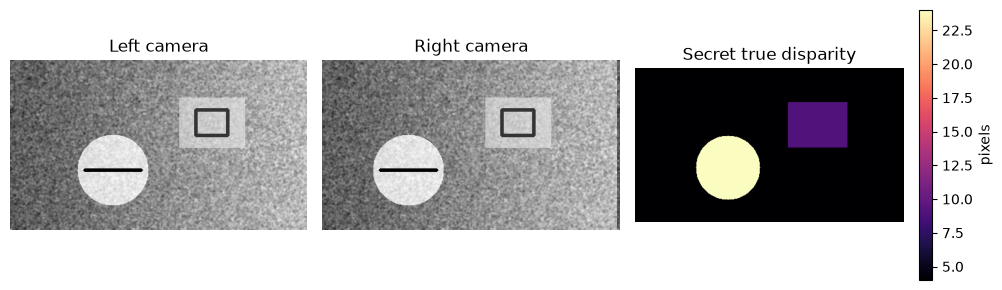

In [2]:
left, right, true_disparity = make_stereo_scene()

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, image, title, cmap in zip(
    axes,
    (left, right, true_disparity),
    ("Left camera", "Right camera", "Secret true disparity"),
    ("gray", "gray", "magma"),
):
    shown = ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(axes[2].images[0], ax=axes[2], fraction=0.046, label="pixels")
plt.tight_layout()
plt.show()

> **What do the disparity colors mean?** They show horizontal shift in **pixels**, not distance in meters. Dark background = `4 px` disparity (farthest), purple rectangle = `9 px`, and bright circle = `24 px` (closest). With the later camera settings `f = 180 px` and `B = 0.12 m`, `Z = fB/d` places them at approximately `5.4 m`, `2.4 m`, and `0.9 m`. So brighter means **more sideways shift and therefore closer**. “Secret” means we created these values ourselves and know the answer before asking StereoBM to guess.

### Follow one object with your eyes

The near circle moves farther left in the right image than the farther rectangle. Nothing in the world moved; the observer moved sideways. Stereo geometry enjoys blaming the camera for everything.

**Practice:** change the disparities `9` and `24` in the scene generator. Predict which object will appear closer before looking at the maps.

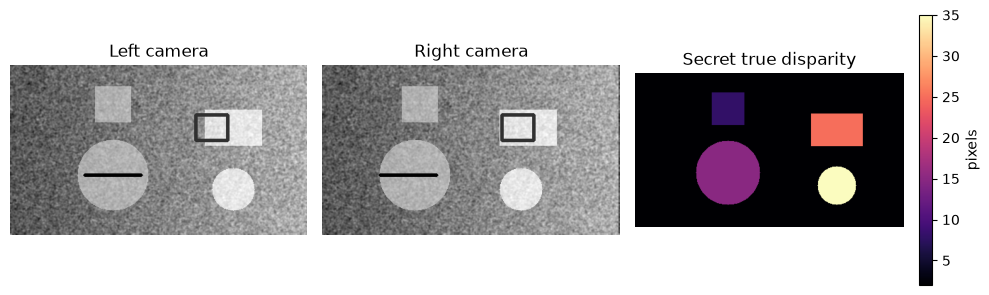

In [3]:
left_p, right_p, true_disparity_p = make_stereo_scene(
    background_shift=2,
    objects=[
        # name, center, size/radius, intensity, disparity, shape
        ("square", (145, 55), (50, 50), 185, 8, "rectangle"),
        ("rec", (315, 88), (80, 50), 225, 25, "rectangle"),
        ("near moon", (315, 175), 30, 225, 35, "circle"),
        ("far moon", (145, 155), 50, 185, 15, "circle"),
    ]
)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, image, title, cmap in zip(
    axes,
    (left_p, right_p, true_disparity_p),
    ("Left camera", "Right camera", "Secret true disparity"),
    ("gray", "gray", "magma"),
):
    shown = ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(axes[2].images[0], ax=axes[2], fraction=0.046, label="pixels")
plt.tight_layout()
plt.show()

## 2. Block matching: slide a small window and distrust everybody

For one patch in the left image, try candidate horizontal shifts in the right image. A simple matcher computes the **Sum of Absolute Differences (SAD)**: subtract corresponding pixel values, take their absolute values, and add them. The shift with the smallest cost wins. SAD is only an acronym; nobody needs to become emotionally involved except perhaps the mismatched pixels.

A single pixel is often ambiguous. A patch provides context—but a larger patch may cross object boundaries and mix different depths. Every solution arrives carrying a smaller problem under its coat.

### What the matcher actually does

For a chosen left-image point `(x, y)`:

1. Build a small patch centred at `(x, y)` in the left image.
2. Start with a candidate patch at the same `(x, y)` in the right image.
3. Keep the same row `y` and move the right patch left one pixel at a time: `(x − 1, y)`, `(x − 2, y)`, and so on.
4. At every position, calculate SAD between the frozen left patch and the current right patch.
5. Choose the right patch with the smallest SAD—the least suspicious candidate.
6. The horizontal shift between the two patch centres is the estimated disparity.

Our search uses disparities from `0` to `40`, so it checks `x`, `x − 1`, …, `x − 40`. For the near circle, the best match moves from `x = 145` to `x = 121`, giving disparity `145 − 121 = 24 px`.

> If manually adding absolute pixel differences becomes your calling: [`sad_cost_curve()` implementation](../../src/wave_part_dual/classical_cv/stereo.py). If drawing lines between suspicious patches is somehow even more exciting: [matching visualization helper](./_helpers/stereo_depth.py).

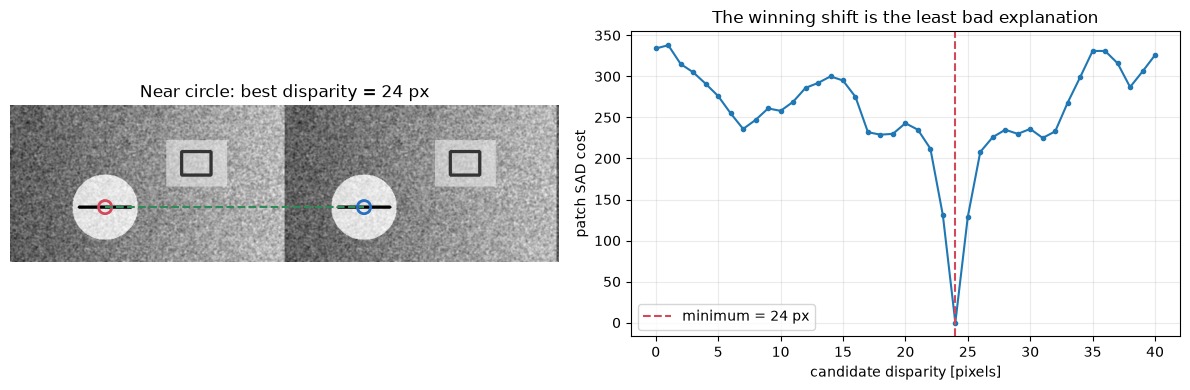

In [4]:
candidate_disparities = np.arange(0, 41)
circle_match = match_and_plot_patch(
    left,
    right,
    match_point=(145, 155),
    candidate_disparities=candidate_disparities,
    block_size=11,
    point_name="Near circle",
)

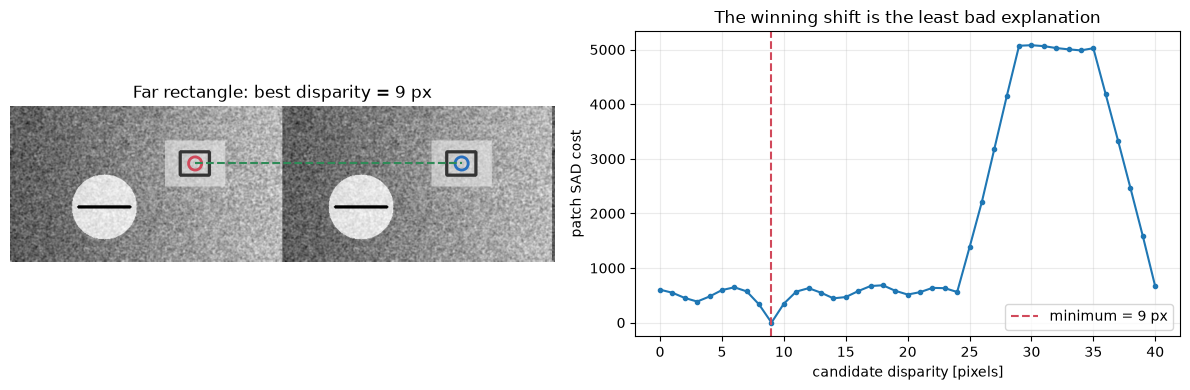

In [5]:
rectangle_match = match_and_plot_patch(
    left,
    right,
    match_point=(285, 88),
    candidate_disparities=candidate_disparities,
    block_size=11,
    point_name="Far rectangle",
)

## 3. From one patch to a disparity map

OpenCV's `StereoBM` repeats block matching across the image. The result is dense-ish rather than truly dense: textureless areas, occlusions, borders, and repeated patterns can produce invalid or noisy estimates.

> **What is texture here?** Texture means **visible local variation**: edges, dots, grain, small brightness changes, or any recognizable arrangement of pixels. It does not necessarily mean that the physical surface feels rough. A polished poster full of letters has excellent visual texture; a rough wall under flat lighting may look almost textureless to the camera.

> **A brief philosophical digression — what does it mean to be textureless?** A textureless area has patches that look nearly identical wherever we place them. The area has not stopped existing or lost its personality; it simply has no distinctive visual address. When every candidate patch says *‘yes, that could be me’*, stereo cannot know which one is telling the truth.

The matcher returns fixed-point disparities scaled by `16`, an OpenCV naming-and-representation trap placed here to keep us emotionally alert.

> Further reading to help everyone sleep peacefully at night: the official [`StereoBM` class and `StereoBM_create()` parameter reference](https://docs.opencv.org/4.x/d9/dba/classcv_1_1StereoBM.html), plus OpenCV's short [stereo depth-map tutorial](https://docs.opencv.org/4.x/dd/d53/tutorial_py_depthmap.html). Their reassuring existence is already doing most of the work.

> **Why does the estimated map have holes?** StereoBM is allowed to say “I do not trust this pixel.” It rejects matches when a patch has too little texture, when several candidate shifts look almost equally good, or when correspondence is impossible near borders and occlusions. We display these invalid values in gray. They mean **unknown disparity**, not a special distance.

> For brave souls who believe three subplots and a colorbar must conceal ancient knowledge: [disparity visualization helper](./_helpers/stereo_depth.py).

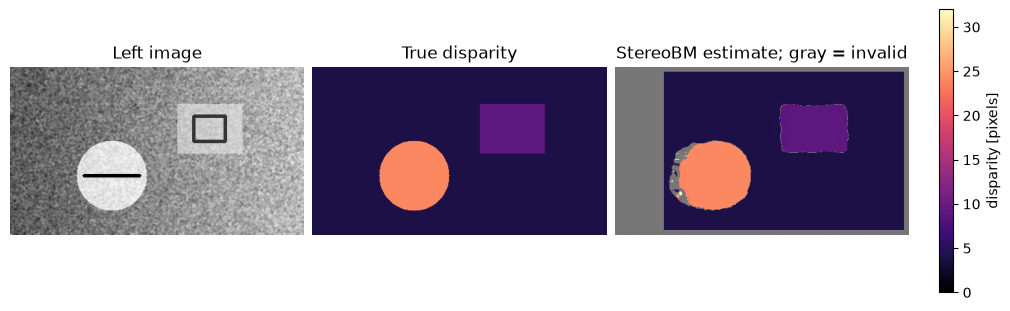

Trusted matches inside the safe area: 98.2%
Mean absolute disparity error for those matches: 0.21 px


In [6]:
# Search disparities 0...63 using a 15×15 comparison block.
num_disparities = 64
block_size = 15
stereo = cv2.StereoBM_create(numDisparities=num_disparities, blockSize=block_size)

# Reject nearly uniform patches: without texture, many horizontal shifts look identical.
stereo.setTextureThreshold(5)

# Accept a match only when the best candidate wins clearly enough over alternatives.
# A larger value is stricter and usually creates more invalid pixels.
stereo.setUniquenessRatio(8)

# OpenCV stores StereoBM disparity with 4 fractional bits, hence division by 16.
estimated_disparity = stereo.compute(left, right).astype(np.float32) / 16.0

# With the default minimum disparity of 0, non-positive values mean no trusted match.
valid_disparity = estimated_disparity > 0

plot_disparity_comparison(
    left,
    true_disparity,
    estimated_disparity,
    valid_disparity,
)

# A block needs half its width around the centre. The left border also needs
# room for the complete 0...63 pixel search in the right image.
block_radius = block_size // 2
left_margin = num_disparities + block_radius
interior = np.zeros_like(valid_disparity)
interior[
    block_radius:-block_radius,
    left_margin:-block_radius,
] = True

# Evaluate only pixels that are inside the safe area and trusted by StereoBM.
evaluation_mask = valid_disparity & interior
trusted_inside_ratio = evaluation_mask.sum() / interior.sum()
mae = np.mean(np.abs(estimated_disparity[evaluation_mask] - true_disparity[evaluation_mask]))
print(f"Trusted matches inside the safe area: {trusted_inside_ratio:.1%}")
print(f"Mean absolute disparity error for those matches: {mae:.2f} px")

> **What is the safe area?** A `15×15` block needs `7 px` around its centre, so the top, bottom, and right edges cannot be evaluated all the way to the border. The left edge loses even more space: StereoBM may search as far as `63 px` left in the right image, so it needs roughly `64 + 7 = 71 px` of room. We exclude those geometrically unfair borders before judging the matcher.

> **What does the percentage mean?** “Trusted matches inside the safe area” is the fraction of those remaining pixels for which StereoBM returned a positive disparity it accepted. The other safe-area pixels were rejected because the texture was weak, the winner was not unique enough, or matching still failed. The reported mean error is calculated only for accepted matches—it measures how accurate the answers were, while the percentage measures how often StereoBM was willing to answer.

### Practice: block-size diplomacy

Compare small and large blocks. Small blocks can preserve boundaries but are easier to confuse; large blocks are steadier but may flatten thin objects and mix foreground with background.

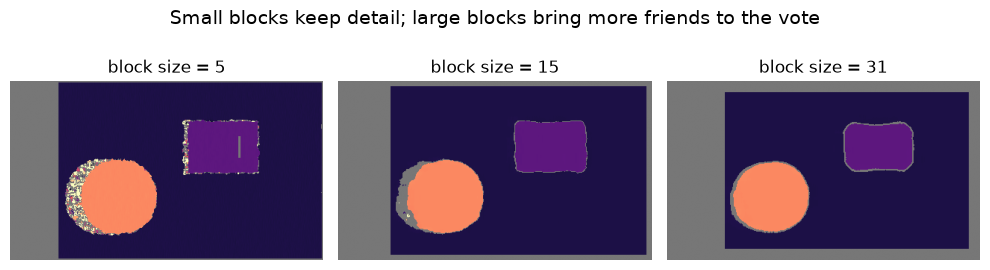

In [7]:
block_sizes = (5, 15, 31)
disparity_cmap = plt.colormaps["magma"].with_extremes(bad="#777777")
fig, axes = plt.subplots(1, len(block_sizes), figsize=(10, 3))
for ax, block_size in zip(axes, block_sizes):
    matcher = cv2.StereoBM_create(numDisparities=64, blockSize=block_size)
    matcher.setTextureThreshold(5)
    disparity = matcher.compute(left, right).astype(np.float32) / 16.0
    ax.imshow(np.where(disparity > 0, disparity, np.nan), cmap=disparity_cmap, vmin=0, vmax=32)
    ax.set_title(f"block size = {block_size}")
    ax.axis("off")
fig.suptitle("Small blocks keep detail; large blocks bring more friends to the vote", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Disparity becomes metric depth

For a rectified pair with focal length `f` in pixels and camera baseline `B` in meters:

The **baseline** is the physical distance between the two camera optical centres—`0.12 m` in our experiment. A larger baseline produces more disparity for the same depth, which can improve distance sensitivity, but it also increases viewpoint differences, occlusions, and the chance that one camera sees something the other does not.

`depth Z = f · B / disparity`

This is why calibration matters again. Disparity is measured from images; focal length and baseline turn it into meters. Depth is inversely proportional to disparity, so one pixel of disparity error becomes increasingly expensive far away.

> The division—and its refusal to assign depth to invalid disparity—lives in [`disparity_to_depth()`](../../src/wave_part_dual/classical_cv/stereo.py). The figure machinery lives with the [notebook helpers](./_helpers/stereo_depth.py), safely away from civilians.

> Brave individuals who want more metric-depth geometry can continue into OpenCV's [stereo depth tutorial](https://docs.opencv.org/4.x/dd/d53/tutorial_py_depthmap.html) and the considerably less bedtime-friendly [`calib3d` reconstruction reference](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html).

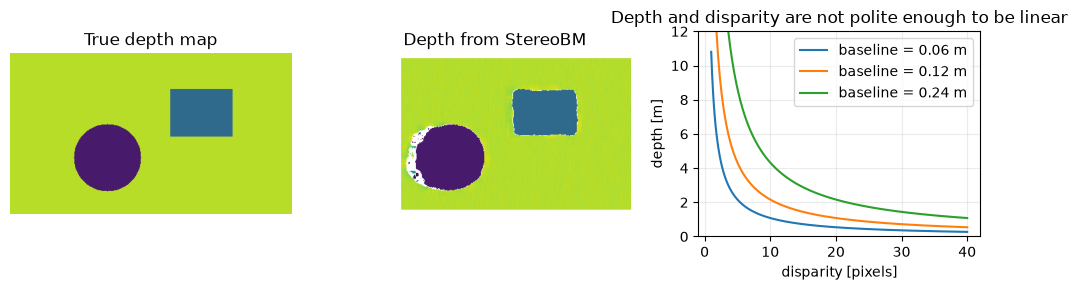

In [8]:
focal_length_px = 180.0
baseline_m = 0.12

true_depth = disparity_to_depth(true_disparity, focal_length_px, baseline_m)
estimated_depth = disparity_to_depth(estimated_disparity, focal_length_px, baseline_m)

plot_depth_geometry(true_depth, estimated_depth, focal_length_px)

## 5. Depth map → point cloud

A depth map stores one distance per pixel. Combine each pixel `(u, v)` with its depth and camera intrinsics, and it becomes a 3D point `(X, Y, Z)` in the camera frame.

The result is a **point cloud**: not a solid object, just many measured surface samples floating together with impressive confidence.

> Curious about the machinery that helps pixels escape into 3D? The actual geometry lives in [`depth_map_to_points()`](../../src/wave_part_dual/classical_cv/stereo.py). If rotating clouds of tiny dots suddenly becomes your calling, the [point-cloud plotting helper](./_helpers/stereo_depth.py) awaits.

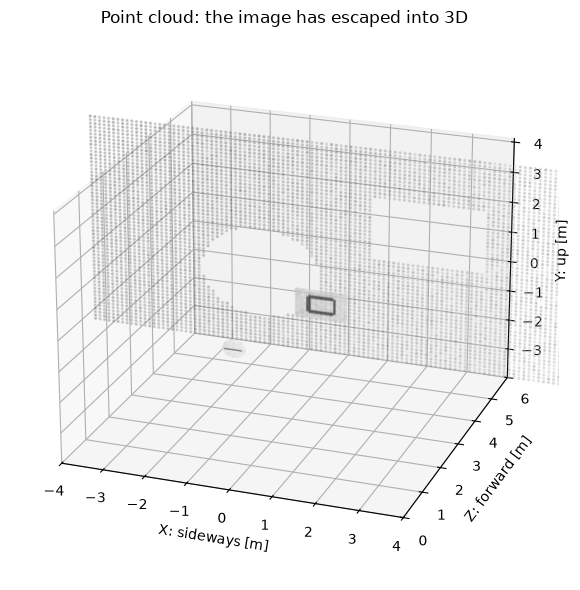

In [9]:
points_3d = depth_map_to_points(true_depth, focal_length_px)
plot_point_cloud(points_3d, left, sample_step=4)

## 6. Practical detour: active infrared rescues textureless surfaces

A common active-stereo device contains **one infrared projector and two infrared cameras**. The projector shines an invisible dot pattern onto the scene; both IR cameras photograph the reflected pattern from slightly different positions and perform the same disparity search we used above.

The dots are **not heat**. They are near-infrared illumination—more like an invisible flashlight covered with freckles. An RGB camera may also be present, but it provides normal color rather than the stereo depth itself.

Why bother? Passive stereo depends on visible texture. A plain wall gives many identical patches, so every candidate shift looks equally plausible. Projected dots make local patches distinctive. The projector does not directly measure distance; it merely gives the two cameras better evidence to argue about.

Sunlight can overwhelm the IR pattern, reflective or transparent surfaces remain troublesome, and multiple active devices may interfere. Technology has once again declined to provide a free lunch.

> If your mental health currently feels suspiciously abundant, you may inspect the [active-IR experiment machinery](./_helpers/stereo_depth.py).

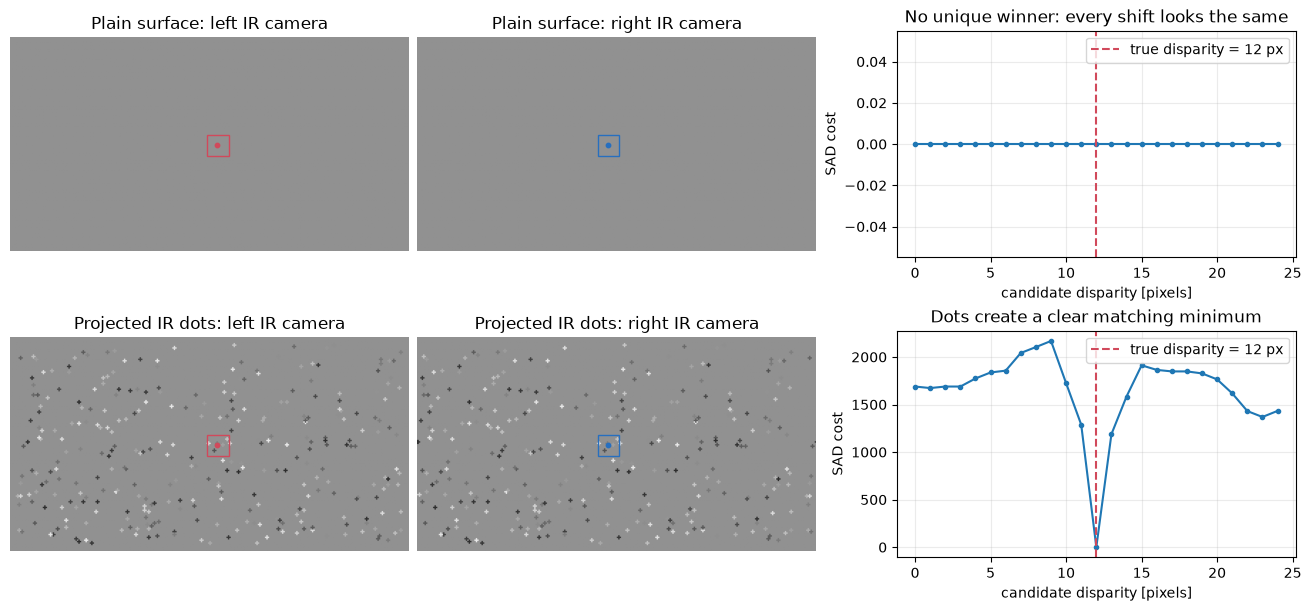

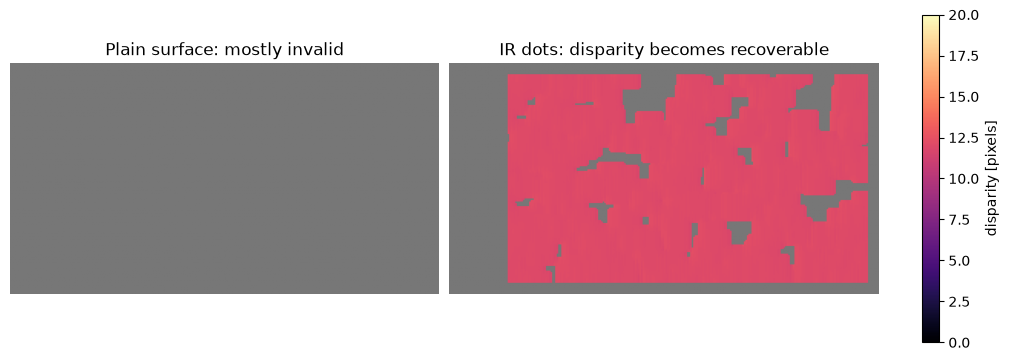

Trusted disparity on plain surface: 0.0%
Trusted disparity with projected dots: 90.6%


In [10]:
active_ir_results = plot_active_ir_experiment(
    projected_disparity=12,
    match_point=(145, 75),
    block_size=15,
)

## 7. Keypoints and descriptors: sparse cousins of dense stereo

Dense stereo tries to estimate disparity for many pixels or patches. Keypoint methods first select distinctive locations—often corners—then describe the surrounding appearance as a vector or binary pattern. Similar descriptors can be matched between images.

This produces sparse correspondences rather than a full depth map. It is useful for tracking, image alignment, recognition, visual odometry, and as raw material for later geometry.

### What is this ORB creature?

In normal-human language, ORB is a two-step machine:

1. **Find memorable spots.** Corners, sharp turns, and unusual local patterns are interesting; plain grey pixels are boring.
2. **Give every spot a tiny binary fingerprint.** ORB examines nearby pixels and produces bits such as `101100...`. Few differing bits between two fingerprints suggest the same physical point; many differing bits suggest strangers who merely met near a camera.

`detectAndCompute()` performs those two steps. `NORM_HAMMING` counts differing fingerprint bits, while `crossCheck=True` keeps a pair only when both spots choose each other.

ORB stands for **Oriented FAST and Rotated BRIEF**—a wonderfully efficient name if your goal is to explain nothing to beginners. The visualization is showing those memorable spots and the agreements found between them.

### ORB controls worth knowing

- `nfeatures`: maximum number of strongest spots to retain—not a promise that the image contains that many.
- `fastThreshold`: lower finds more weak spots; higher keeps only stronger ones.
- The remaining controls can stay under the floorboards until we actually need them.

Further reading, mainly to provide comfort through its mere existence: [OpenCV ORB parameters](https://docs.opencv.org/4.x/db/d95/classcv_1_1ORB.html) and [OpenCV feature matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html).


### Two ORB knobs, without summoning the whole control panel

We change **one parameter at a time** on the same left image. The first row changes how many of the strongest points ORB may keep. The second changes how easily a point is accepted in the first place. The markers show detected locations; their count is the important part here.

> If descriptor-index bookkeeping suddenly sounds like a pleasant evening, the [ORB visualization helpers](./_helpers/stereo_depth.py) are available.

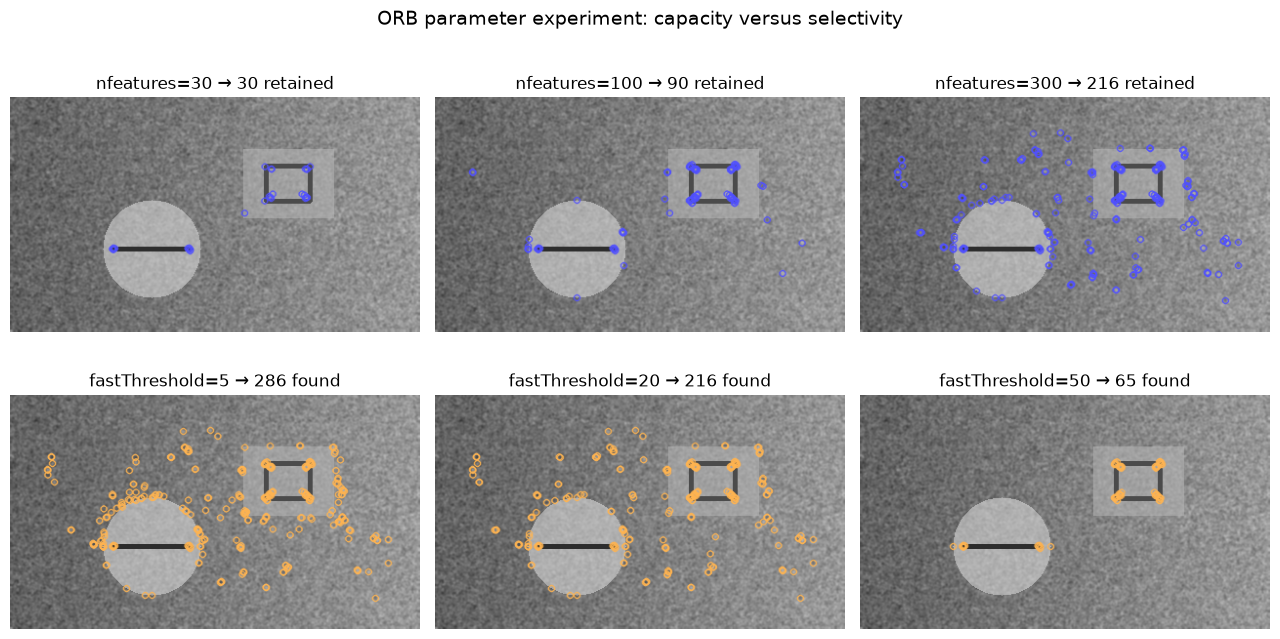

In [11]:
plot_orb_parameter_sweep(
    left,
    nfeatures_values=(30, 100, 300),
    fast_threshold_values=(5, 20, 50),
)

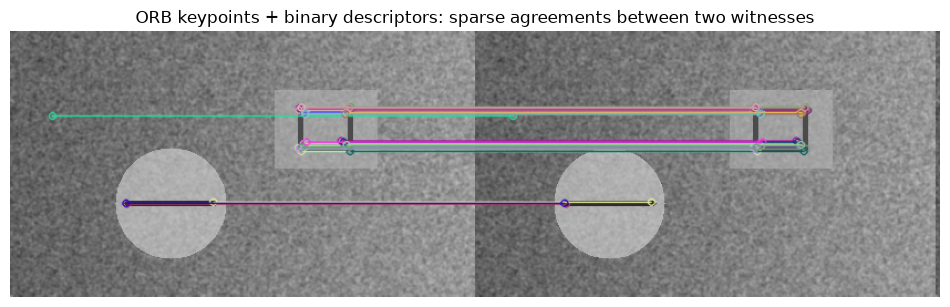

Detected keypoints: left=90, right=90
Median vertical mismatch among shown matches: 0.00 px


In [12]:
orb_match_results = plot_orb_matches(
    left,
    right,
    nfeatures=100,
    max_matches=35,
)

## Quick reflection

- Why does rectification reduce matching from a 2D search to a mostly horizontal search?
    - Rectification transforms both images so matching points lie on the same row. The search can then move mostly left and right instead of everywhere.
- Why does a nearby object have larger disparity?
    - A nearby point shifts more between the two camera views, so its disparity is larger.
- Why can a large matching block damage object boundaries?
    - A large block may mix foreground and background pixels that belong to different depths.
- Which quantities convert disparity from pixels into depth in meters?
    - Focal length and camera baseline convert the measured disparity into metric depth.
- Why does active infrared help on a plain wall?
    - The projected dots add artificial visual texture that both IR cameras can match.
- What is the difference between a keypoint and its descriptor?
    - A keypoint says **where** an interesting spot is; its descriptor records **what the nearby pixels look like**.

## Takeaway

Stereo depth is not produced by two cameras merely existing near each other. The system must find corresponding evidence, measure disparity, know its calibration, and survive ambiguity, textureless surfaces, occlusion, and noise.

Two cameras can estimate distance. They can also disagree in stereo.